In [ ]:
"""1. Introduction
Unemployment Analysis with Python is a data analysis project that examines unemployment trends in India. It helps identify regional differences and understand changes in unemployment rates before and after COVID-19."""

In [ ]:
"""2. Objective
1.Analyze unemployment rates across Indian states.
2.Identify monthly and yearly trends.
3.Compare pre-COVID and post-COVID unemployment rates.
4.Visualize patterns using charts and graphs."""

In [ ]:
"""3. Dataset
The Unemployment in India dataset is obtained from Kaggle. It contains information about regions, dates, unemployment rates, estimated employment, and labour participation rates."""

In [ ]:
"""4. Tools and Technology
1.Python: Programming language.
2.Pandas: Data cleaning and analysis.
3.NumPy: Numerical operations.
4.Matplotlib: Data visualization.
5.Seaborn: Statistical charts and heatmaps.
6. Writing and executing code."""

In [ ]:
"""5. Project Workflow
1.Download and load the dataset.
2.Inspect and clean the data.
3.Handle missing values and convert data types.
4.Perform exploratory data analysis (EDA).
5.Create charts and visualizations.
6.Compare pre-COVID and post-COVID unemployment rates.
7.Interpret results and draw conclusions."""

In [ ]:
"""6. Expected Outcome
The project is expected to identify unemployment trends across Indian states, highlight changes over time, compare unemployment rates before and after COVID-19, and present meaningful insights through visualizations."""

In [1]:
#1. Install and Import Libraries
# Install required libraries if needed
# Run this command only if the libraries are not installed:
# !pip install pandas numpy matplotlib seaborn jupyter

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# 2. Load the Dataset
 # Load dataset
df = pd.read_csv("/content/Unemployment in India.csv")

# Display first five rows
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [5]:
#3. Inspect the Dataset
# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display first 10 rows
display(df.head(10))

Dataset Shape: (768, 7)

Column Names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000



Missing Values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
5,Andhra Pradesh,31-10-2019,Monthly,3.52,12017412.0,43.01,Rural
6,Andhra Pradesh,30-11-2019,Monthly,4.12,11397681.0,41.00,Rural
7,Andhra Pradesh,31-12-2019,Monthly,4.38,12528395.0,45.14,Rural
8,Andhra Pradesh,31-01-2020,Monthly,4.84,12016676.0,43.46,Rural
9,Andhra Pradesh,29-02-2020,Monthly,5.91,11723617.0,42.83,Rural


In [6]:
#4. Clean the Dataset
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove leading and trailing spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Rename columns to standard names
df.rename(columns={
    "Region": "Region",
    "Date": "Date",
    "Frequency": "Frequency",
    "Estimated Unemployment Rate (%)": "Unemployment_Rate",
    "Estimated Employed": "Employed",
    "Estimated Labour Participation Rate (%)": "Labour_Participation_Rate",
    "Area": "Area"
}, inplace=True)

# Convert numerical columns
numeric_columns = [
    "Unemployment_Rate",
    "Employed",
    "Labour_Participation_Rate"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert date column
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(
        df["Date"], dayfirst=True, errors="coerce"
    )

# Check missing values after conversion
print("Missing values after conversion:")
print(df.isnull().sum())

# Remove rows missing essential analysis fields
required_columns = [
    "Region",
    "Date",
    "Unemployment_Rate",
    "Employed",
    "Labour_Participation_Rate"
]

df = df.dropna(subset=required_columns).copy()

# Sort data by date
df = df.sort_values("Date").reset_index(drop=True)

print("\nDataset cleaned successfully!")
print("Cleaned dataset shape:", df.shape)

display(df.head())

Missing values after conversion:
Region                       28
Date                         28
Frequency                    28
Unemployment_Rate            28
Employed                     28
Labour_Participation_Rate    28
Area                         28
dtype: int64

Dataset cleaned successfully!
Cleaned dataset shape: (740, 7)


,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation_Rate,Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural
2,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural
3,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural
4,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural


Average Unemployment Rate by Region:


,Unemployment_Rate
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


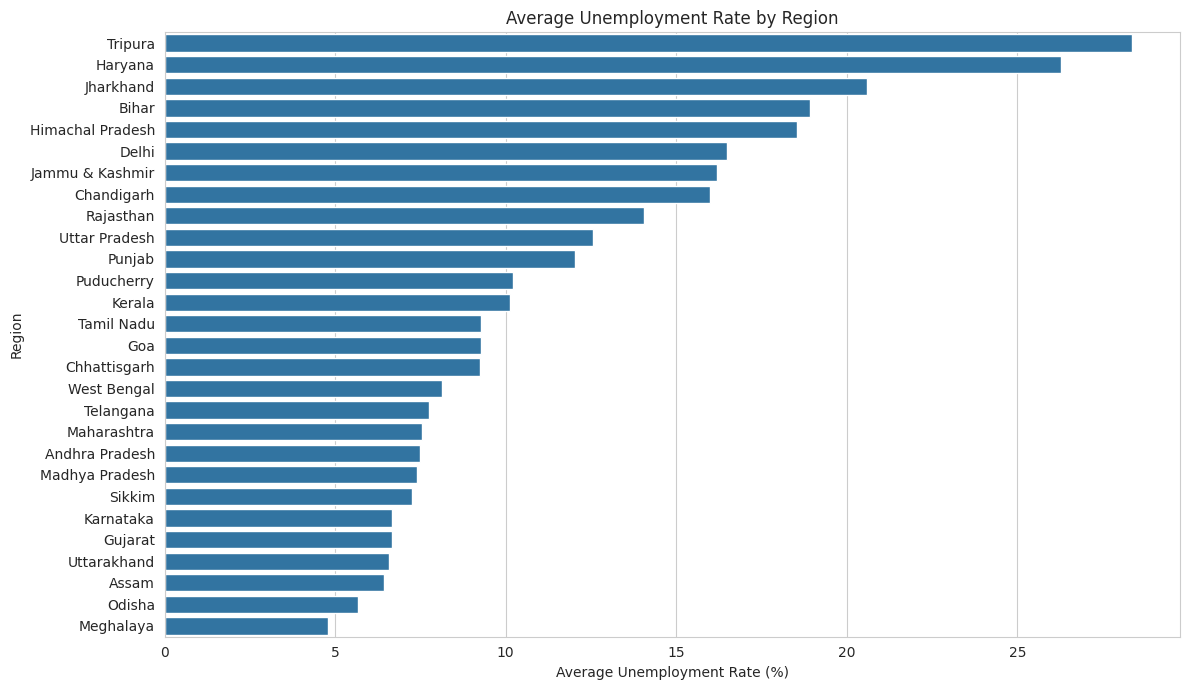

In [8]:
#5. Exploratory Data Analysis (EDA)
#A. Average Unemployment Rate by Region
# Calculate average unemployment rate for each region
region_unemployment = (
    df.groupby("Region")["Unemployment_Rate"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Unemployment Rate by Region:")
display(region_unemployment.to_frame())

# Visualize regional unemployment
plt.figure(figsize=(12, 7))

sns.barplot(
    x=region_unemployment.values,
    y=region_unemployment.index
)

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

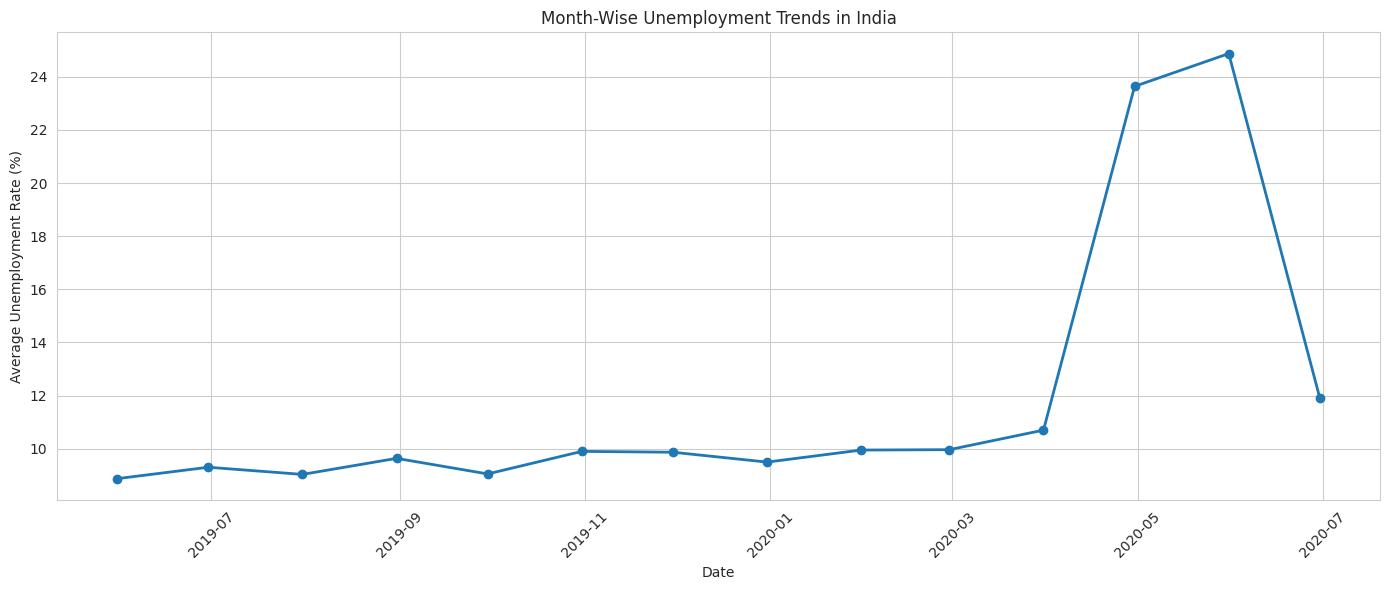

In [9]:
#B. Month-Wise Unemployment Trends
# Extract month and year
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

# Calculate monthly average unemployment rate
monthly_unemployment = (
    df.groupby("Date")["Unemployment_Rate"]
    .mean()
    .sort_index()
)

# Plot monthly trends
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o",
    linewidth=2
)

plt.title("Month-Wise Unemployment Trends in India")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

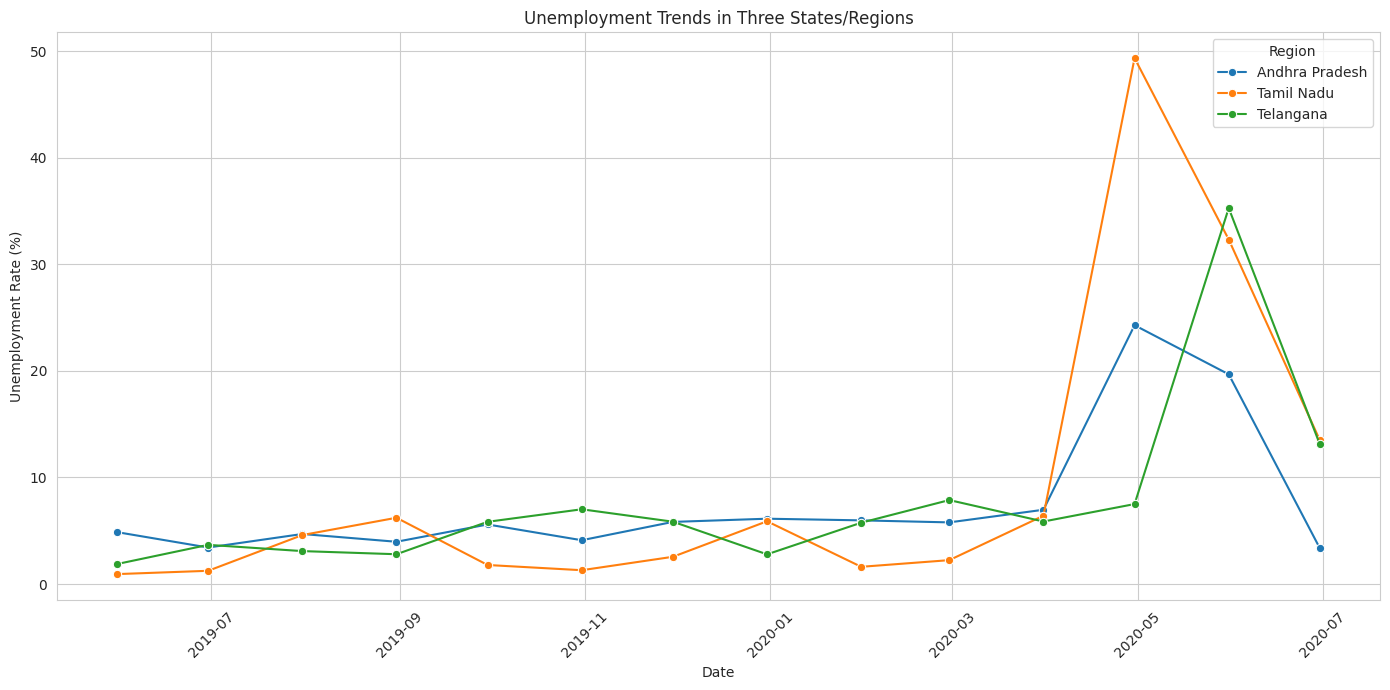

States/regions included: ['Andhra Pradesh', 'Telangana', 'Tamil Nadu']


In [10]:
#6. Time-Series Line Chart for Three Major States
# Select three states with the most observations
top_states = df["Region"].value_counts().head(3).index.tolist()

# Calculate state-wise unemployment rates over time
state_trends = (
    df[df["Region"].isin(top_states)]
    .groupby(["Date", "Region"])["Unemployment_Rate"]
    .mean()
    .reset_index()
)

# Plot state-wise trends
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=state_trends,
    x="Date",
    y="Unemployment_Rate",
    hue="Region",
    marker="o"
)

plt.title("Unemployment Trends in Three States/Regions")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.legend(title="Region")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("States/regions included:", top_states)

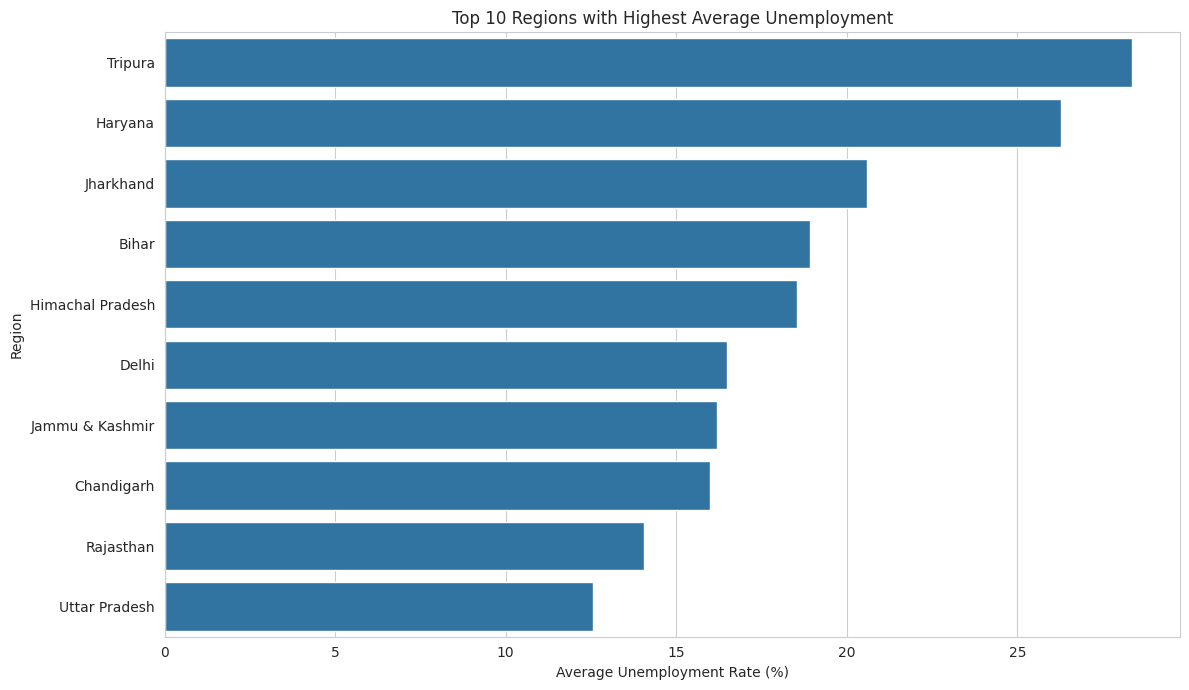

,Average Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


In [11]:
#7. Bar Chart: Top 10 States with Highest Unemployment
# Calculate average unemployment by state/region
average_unemployment = (
    df.groupby("Region")["Unemployment_Rate"]
    .mean()
    .sort_values(ascending=False)
)

# Select the top 10 regions
top_10_regions = average_unemployment.head(10)

# Plot bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_10_regions.values,
    y=top_10_regions.index
)

plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# Display results
display(top_10_regions.to_frame(name="Average Unemployment Rate (%)"))

Correlation Matrix:


,Unemployment_Rate,Employed,Labour_Participation_Rate
Unemployment_Rate,1.000000,-0.222876,0.002558
Employed,-0.222876,1.000000,0.011300
Labour_Participation_Rate,0.002558,0.011300,1.000000


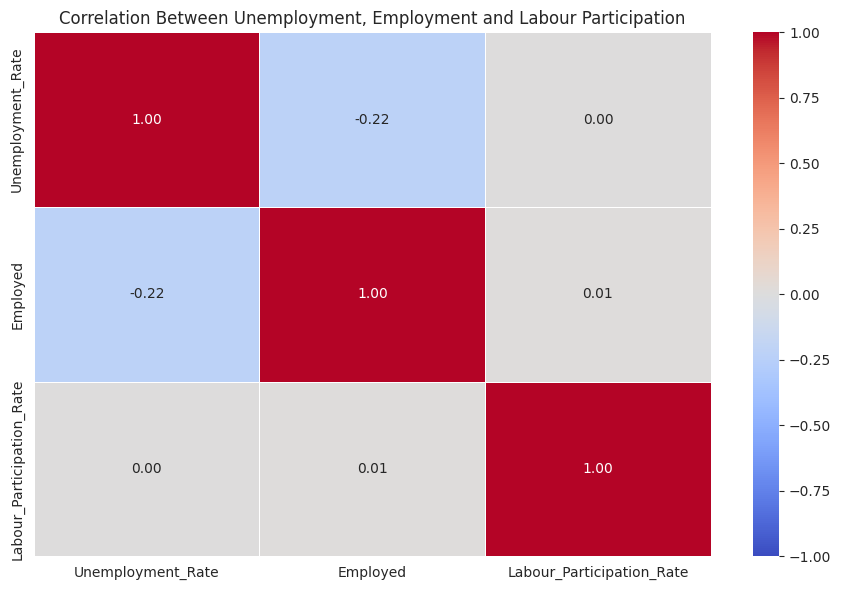

In [13]:
#8. Heatmap: Correlation Analysis
# Select numerical columns
correlation_columns = [
    "Unemployment_Rate",
    "Employed",
    "Labour_Participation_Rate"
]

# Calculate correlation matrix
correlation_matrix = df[correlation_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix)

# Plot heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Unemployment, Employment and Labour Participation")
plt.tight_layout()
plt.show()

Average Unemployment Rate: Pre-COVID vs Post-COVID


,Average Unemployment Rate (%)
Period,
Pre-COVID,9.509534
Post-COVID,17.774363


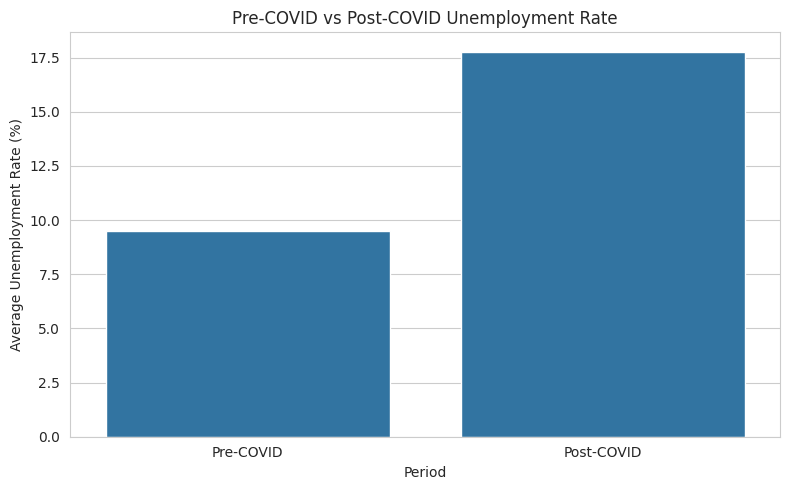

Difference in average unemployment rate: 8.26 percentage points
The average unemployment rate was higher in the post-COVID period.


In [14]:
#9. Pre-COVID vs Post-COVID Comparison
# Define the COVID-19 comparison periods
covid_start = pd.Timestamp("2020-03-01")

df["Period"] = np.where(
    df["Date"] < covid_start,
    "Pre-COVID",
    "Post-COVID"
)

# Calculate average unemployment rate for each period
period_comparison = (
    df.groupby("Period")["Unemployment_Rate"]
    .mean()
    .reindex(["Pre-COVID", "Post-COVID"])
)

print("Average Unemployment Rate: Pre-COVID vs Post-COVID")
display(period_comparison.to_frame(name="Average Unemployment Rate (%)"))

# Plot comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    x=period_comparison.index,
    y=period_comparison.values
)

plt.title("Pre-COVID vs Post-COVID Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

# Calculate difference
if period_comparison.notna().all():
    difference = (
        period_comparison["Post-COVID"]
        - period_comparison["Pre-COVID"]
    )

    print(f"Difference in average unemployment rate: {difference:.2f} percentage points")

    if difference > 0:
        print("The average unemployment rate was higher in the post-COVID period.")
    elif difference < 0:
        print("The average unemployment rate was lower in the post-COVID period.")
    else:
        print("The average unemployment rates were equal in both periods.")
else:
    print("One or both periods contain no valid observations.")

Year-Wise Average Unemployment Rate:


,Unemployment_Rate
Year,
2019,9.399047
2020,15.101581


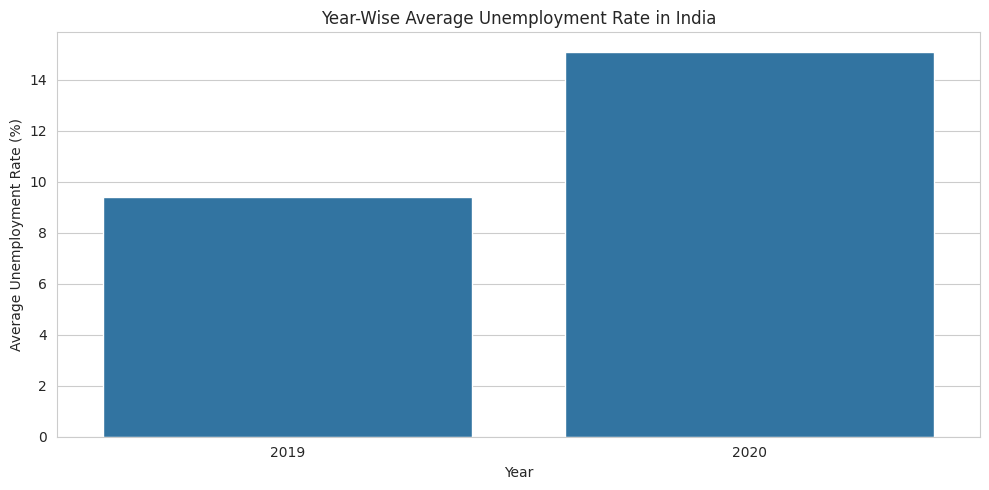

In [15]:
#10. Year-Wise Unemployment Analysis
# Calculate average unemployment rate by year
yearly_unemployment = (
    df.groupby("Year")["Unemployment_Rate"]
    .mean()
)

print("Year-Wise Average Unemployment Rate:")
display(yearly_unemployment.to_frame())

# Plot yearly unemployment
plt.figure(figsize=(10, 5))

sns.barplot(
    x=yearly_unemployment.index.astype(str),
    y=yearly_unemployment.values
)

plt.title("Year-Wise Average Unemployment Rate in India")
plt.xlabel("Year")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

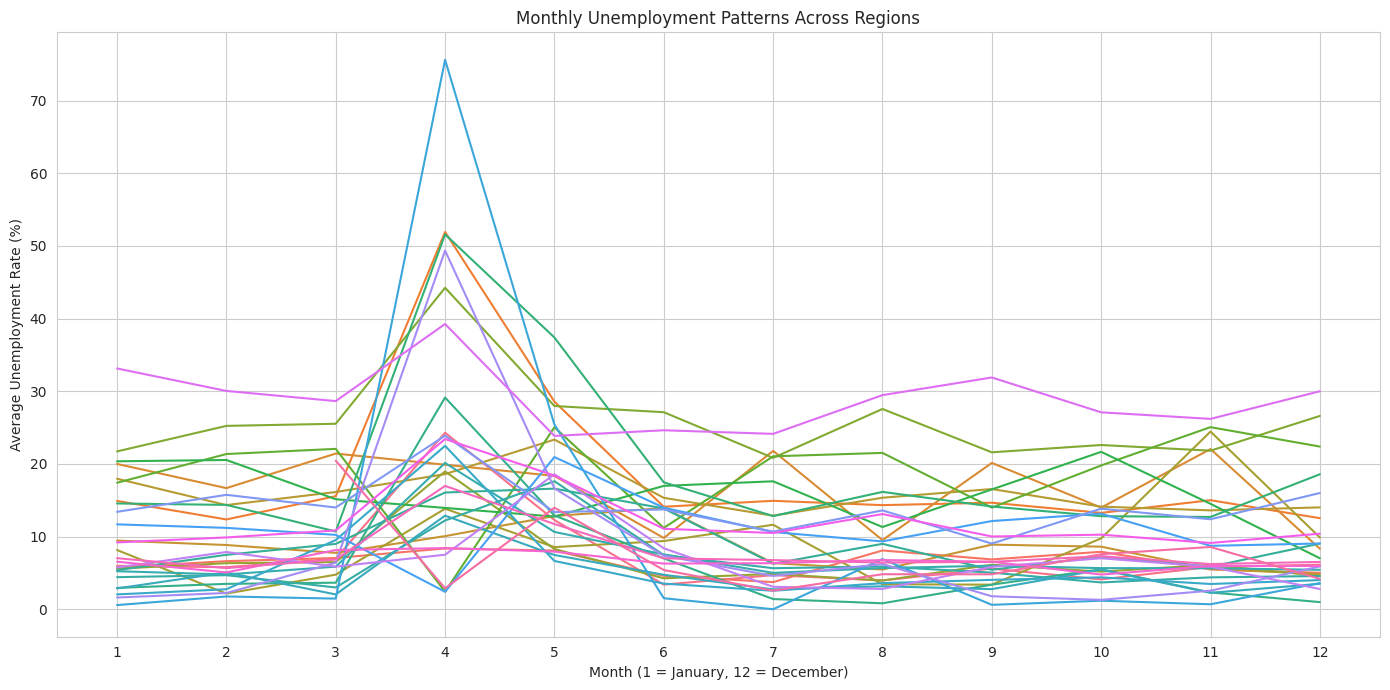

In [16]:
#11. Monthly Unemployment by Region
# Calculate average unemployment by month and region
monthly_region = (
    df.groupby(["Month", "Region"])["Unemployment_Rate"]
    .mean()
    .reset_index()
)

# Plot the monthly trends
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=monthly_region,
    x="Month",
    y="Unemployment_Rate",
    hue="Region",
    legend=False
)

plt.title("Monthly Unemployment Patterns Across Regions")
plt.xlabel("Month (1 = January, 12 = December)")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [17]:
#12. Generate Automatic Summary Statistics
# Overall statistics
print("========== UNEMPLOYMENT ANALYSIS SUMMARY ==========")

print(f"Total records analyzed: {len(df)}")
print(f"Number of regions: {df['Region'].nunique()}")

print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

print(
    f"Overall average unemployment rate: "
    f"{df['Unemployment_Rate'].mean():.2f}%"
)

print(
    f"Highest recorded unemployment rate: "
    f"{df['Unemployment_Rate'].max():.2f}%"
)

print(
    f"Lowest recorded unemployment rate: "
    f"{df['Unemployment_Rate'].min():.2f}%"
)

print("\nRegion with highest average unemployment:")
print(average_unemployment.index[0])
print(f"{average_unemployment.iloc[0]:.2f}%")

print("\nRegion with lowest average unemployment:")
print(average_unemployment.index[-1])
print(f"{average_unemployment.iloc[-1]:.2f}%")

========== UNEMPLOYMENT ANALYSIS SUMMARY ==========
Total records analyzed: 740
Number of regions: 28
Date range: 2019-05-31 to 2020-06-30
Overall average unemployment rate: 11.79%
Highest recorded unemployment rate: 76.74%
Lowest recorded unemployment rate: 0.00%

Region with highest average unemployment:
Tripura
28.35%

Region with lowest average unemployment:
Meghalaya
4.80%


In [18]:
#13. Save the Cleaned Dataset
# Save cleaned dataset
df.to_csv("cleaned_unemployment_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


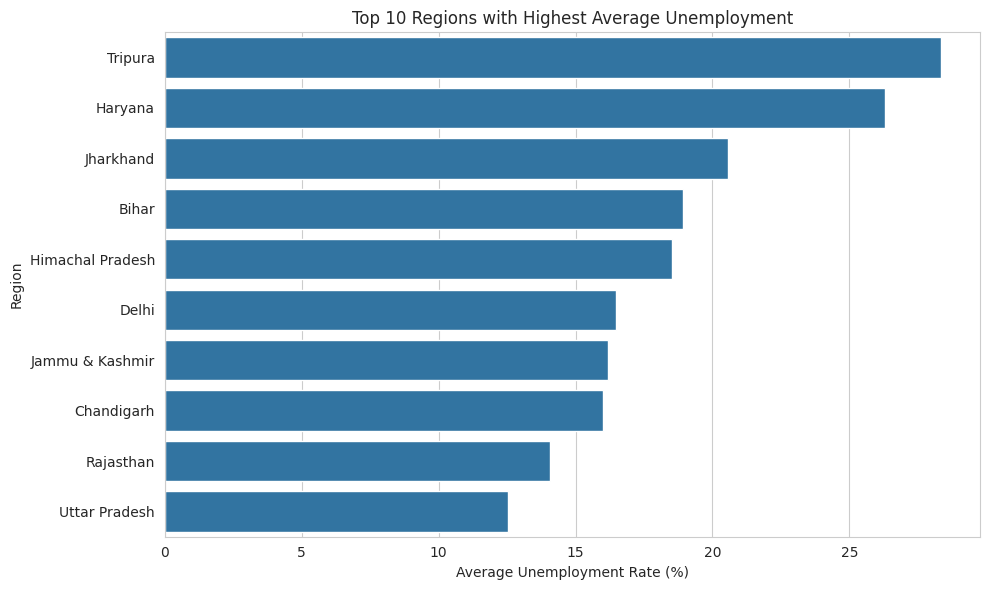

In [19]:
#14. Save Your Graphs
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_regions.values,
    y=top_10_regions.index
)

plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.savefig("top_10_unemployment_regions.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
"""Conclusion
This project analyzes unemployment trends in India using Python. It highlights regional differences and changes in unemployment rates before and after COVID-19 through data visualization."""